# Retriever Evaluation — is the fine-tuned model good?

**Evaluation only.** This notebook does *not* fine-tune or re-train anything. It reuses the
artifacts already produced by `embedding_finetune_908chunks.ipynb` (Part 2) and scores the
retrievers against the gold labels.

It answers two questions:
1. **Did fine-tuning help?** — compare `e5 zero-shot` vs `e5 fine-tuned`.
2. **Is it robust?** — re-score on *reworded* questions and report the DROP.

### What it reuses (must already exist on disk)
| Artifact | Purpose |
|---|---|
| `data/khmer_history_chunks.json` (+ train/test) | corpus, `ids`, `texts` |
| `emb_e5.npy` | e5 zero-shot vectors (the "before") |
| `emb_ft.npy` | fine-tuned vectors (the "after") |
| `khmer-retriever-finetuned/` | fine-tuned model, to encode the questions |
| `data/gold_draft.csv` | question → correct chunk_id labels |
| `data/gold_test_paraphrased.csv` | reworded questions (robustness test) |

### Metrics (ranking, not classification — so no confusion matrix)
- **Recall@k** — is the gold chunk in the top k? (k = 1, 3, 5)
- **MRR@10** — 1 / rank of the gold chunk, averaged.

> Dependencies: install via `requirements.txt` (CUDA torch first — see that file).
> The notebook auto-detects the GPU and runs on it.

## 1. Setup — imports, constants, GPU detection

In [1]:
import torch
print(torch.cuda.is_available(), torch.version.cuda)

True 12.4


In [2]:
import os, json, time
import numpy as np
import pandas as pd
import torch

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- GPU selection: use the NVIDIA GPU when available ---
if torch.cuda.is_available():
  DEVICE = "cuda"
  print("device: cuda ->", torch.cuda.get_device_name(0))
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
  DEVICE = "mps"
  print("device: mps (Apple)")
else:
  DEVICE = "cpu"
  print("WARNING: no GPU found, running on CPU (slower). "
      "Install CUDA torch per requirements.txt to use your RTX 4070.")

# Must match the models/settings used when the artifacts were produced (Part 2).
TRAIN_MODEL = "intfloat/multilingual-e5-small"   # the base model that was fine-tuned
FT_MODEL_DIR = "khmer-retriever-finetuned"        # the saved fine-tuned model folder
E5_Q, E5_P = "query: ", "passage: "               # e5 REQUIRES these exact prefixes
TOP_K = 5

print("torch", torch.__version__, "| top_k =", TOP_K)

device: cuda -> NVIDIA GeForce RTX 4070 Laptop GPU
torch 2.6.0+cu124 | top_k = 5


## 2. Load corpus + labels, and verify the cache is not stale

`chunks.sig` is an MD5 fingerprint of all chunk_ids. If it no longer matches the current
corpus, the cached `.npy` vectors belong to a different chunk set and every row would point
at the wrong passage. We refuse to trust stale vectors.

In [3]:
import hashlib

chunks_all   = json.load(open("./data/khmer_history_chunks.json", encoding="utf-8"))
train_chunks = json.load(open("./data/khmer_history_train.json",  encoding="utf-8"))
test_chunks  = json.load(open("./data/khmer_history_test.json",   encoding="utf-8"))

texts = [c["text_for_embedding"] for c in chunks_all]
ids   = [c["chunk_id"] for c in chunks_all]
assert len(set(ids)) == len(ids), "duplicate chunk_id in corpus"

# --- cache fingerprint check (read-only; we never delete anything here) ---
sig  = hashlib.md5("".join(ids).encode()).hexdigest()[:8]
prev = open("chunks.sig").read().strip() if os.path.exists("chunks.sig") else None
if prev != sig:
    print(f"WARNING: chunks.sig ({prev}) != current corpus ({sig}). "
          f"The cached emb_*.npy may be STALE. Re-run Part 2 to rebuild them.")
else:
    print(f"cache fingerprint OK ({sig})")

# --- gold labels: question -> correct chunk_id ---
gold = pd.read_csv("./data/gold_draft.csv", encoding="utf-8-sig")
gold["chunk_id"] = gold["chunk_id"].astype(str).str.strip()
gold["question"] = gold["question"].astype(str).str.strip()
gold = gold[gold["chunk_id"].isin(set(ids))].reset_index(drop=True)

# evaluate on the TEST split only (questions whose gold chunk is a held-out chunk)
test_ids  = {c["chunk_id"] for c in test_chunks}
gold_test = gold[gold["chunk_id"].isin(test_ids)].reset_index(drop=True)

print(f"corpus: {len(chunks_all)} chunks | gold questions: {len(gold)} "
      f"| test questions: {len(gold_test)}")

cache fingerprint OK (be89750a)
corpus: 908 chunks | gold questions: 164 | test questions: 59


## 3. Load the cached vectors and the models

- `emb_e5.npy`  = vectors from the **zero-shot** (untrained) e5  → the *before*.
- `emb_ft.npy`  = vectors from the **fine-tuned** e5            → the *after*.
- We also load both **models** so we can encode the incoming *questions* at query time.

In [4]:
from sentence_transformers import SentenceTransformer

def load_matrix(path, label):
  assert os.path.exists(path), f"missing {path} — run Part 2 first to produce it"
  m = np.load(path)
  assert m.shape[0] == len(ids), (
    f"{label}: matrix has {m.shape[0]} rows but corpus has {len(ids)} chunks — stale cache")
  print(f"{label}: {m.shape}")
  return m

emb_e5 = load_matrix("emb_e5.npy", "emb_e5 (zero-shot)")
emb_ft = load_matrix("emb_ft.npy", "emb_ft (fine-tuned)")

print("\nloading models (first run downloads the base e5 ~450MB)...")
e5 = SentenceTransformer(TRAIN_MODEL, device=DEVICE)                 # base, for zero-shot queries
assert os.path.isdir(FT_MODEL_DIR), f"missing {FT_MODEL_DIR}/ — run Part 2 fine-tune first"
ft = SentenceTransformer(FT_MODEL_DIR, device=DEVICE)                # fine-tuned, for ft queries
print("models ready on", DEVICE)

d:\School\AUPP\2026\Fall\NLP\Khmer_History_retrieval_argumented_generation\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


emb_e5 (zero-shot): (908, 384)
emb_ft (fine-tuned): (908, 384)

loading models (first run downloads the base e5 ~450MB)...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4064.35it/s]


models ready on cuda


## 4. Build the retrievers

A *retriever* = model (to encode the query) + a vector matrix (the index) + search logic.
Vectors are unit-normalised, so a dot product IS cosine similarity.

BM25 (lexical) + Hybrid are built only if `rank_bm25` and `khmer-nltk` are installed; if not,
they are skipped and the dense comparison — which already answers "did fine-tuning help?" —
still runs.

In [5]:
def dense_search(model, matrix, query, k=TOP_K, prefix=""):
    q = model.encode([prefix + query], normalize_embeddings=True)[0]
    scores = matrix @ q
    top = np.argpartition(-scores, k)[:k]          # top-k without a full sort of 908
    top = top[np.argsort(-scores[top])]
    return [(ids[i], float(scores[i])) for i in top]

search_e5 = lambda q, k=TOP_K: dense_search(e5, emb_e5, q, k, E5_Q)   # zero-shot
search_ft = lambda q, k=TOP_K: dense_search(ft, emb_ft, q, k, E5_Q)   # fine-tuned

# --- optional: BM25 (lexical) + hybrid ---
search_bm25 = None
try:
    from rank_bm25 import BM25Okapi
    from khmernltk import word_tokenize

    STOP = {"និង", "នៅ", "ជា", "នៃ", "ដែល", "នេះ", "មួយ", "កា", "ភាព", "ការ",
            "របស់", "បាន", "ទៅ", "ពី", "ពេល", "មក", "។", " ", ""}

    def km_tokens(text):
        toks = [w for w in word_tokenize(text) if w.strip() and w not in STOP]
        return toks + [f"{a}_{b}" for a, b in zip(toks, toks[1:])]

    t0 = time.time()
    bm25 = BM25Okapi([km_tokens(c["text_payload"]) for c in chunks_all])
    print(f"BM25 index built in {time.time()-t0:.0f}s")

    def search_bm25(query, k=TOP_K):
        scores = bm25.get_scores(km_tokens(query))
        top = np.argsort(-scores)[:k]
        return [(ids[i], float(scores[i])) for i in top]
except Exception as e:
    print("BM25/hybrid skipped (install rank-bm25 + khmer-nltk to enable):", e)

def make_hybrid(dense_fn, c=60):
    """Reciprocal rank fusion: merge by rank position, not raw score."""
    def f(query, k=TOP_K):
        fused = {}
        for fn in (search_bm25, dense_fn):
            for rank, (cid, _) in enumerate(fn(query, 20)):
                fused[cid] = fused.get(cid, 0) + 1 / (c + rank + 1)
        return sorted(fused.items(), key=lambda x: -x[1])[:k]
    return f

# assemble the systems to compare
systems = {
    "e5-small (zero-shot)":  search_e5,
    "e5-small (fine-tuned)": search_ft,
}
if search_bm25 is not None:
    systems = {
        "BM25 (lexical)":            search_bm25,
        "e5-small (zero-shot)":      search_e5,
        "e5-small (fine-tuned)":     search_ft,
        "Hybrid (BM25 + fine-tuned)": make_hybrid(search_ft),
    }
print("systems to evaluate:", list(systems))

| 2026-11-03 09:45:49,361 | INFO | khmer-nltk | Loaded model from d:\School\AUPP\2026\Fall\NLP\Khmer_History_retrieval_argumented_generation\.venv\lib\site-packages\khmernltk\word_tokenize\sklearn_crf_ner_10000.sav |


BM25 index built in 14s
systems to evaluate: ['BM25 (lexical)', 'e5-small (zero-shot)', 'e5-small (fine-tuned)', 'Hybrid (BM25 + fine-tuned)']


## 5. The metric — Recall@k and MRR

For each question: ask the retriever, find WHERE the gold chunk landed, record its rank.
- **Recall@k** = share of questions whose gold chunk is in the top k.
- **MRR@10**   = average of 1/rank (0 if the gold chunk is outside the top 10).

Same definition as Part 2, so the numbers are directly comparable.

In [6]:
def evaluate(search_fn, df, k=10):
    ranks = []
    for r in df.itertuples():
        got = [cid for cid, _ in search_fn(r.question, k)]
        ranks.append(got.index(r.chunk_id) + 1 if r.chunk_id in got else 999)
    ranks = np.array(ranks)
    return {"Recall@1": float((ranks == 1).mean()),
            "Recall@3": float((ranks <= 3).mean()),
            "Recall@5": float((ranks <= 5).mean()),
            "MRR@10":   float(np.where(ranks <= k, 1 / ranks, 0).mean()),
            "n":        len(df)}

## 6. Evaluate on the original test questions

In [7]:
results = pd.DataFrame({name: evaluate(fn, gold_test) for name, fn in systems.items()}).T
results = results.astype({"n": int})
results.round(4).to_csv("eval_results_original.csv", encoding="utf-8-sig")
print("saved -> eval_results_original.csv\n")
results.round(3)

saved -> eval_results_original.csv



,Recall@1,Recall@3,Recall@5,MRR@10,n
BM25 (lexical),0.814,1.000,1.000,0.895,59
e5-small (zero-shot),0.508,0.763,0.814,0.637,59
e5-small (fine-tuned),0.576,0.814,0.864,0.700,59
Hybrid (BM25 + fine-tuned),0.763,0.966,0.983,0.856,59


## 7. Robustness — reworded questions and the DROP

Same questions, different words, same correct chunk. A small drop means the retriever matched
on **meaning**; a large drop means it was leaning on literal **word overlap**.

In [8]:
para = pd.read_csv("./data/gold_test_paraphrased.csv", encoding="utf-8-sig")
para["chunk_id"] = para["chunk_id"].astype(str).str.strip()
para["question"] = para["question"].astype(str).str.strip()
assert set(para["chunk_id"]) <= set(ids), "paraphrase file is stale — chunk_ids changed"
print(f"{len(para)} paraphrased questions over {para['chunk_id'].nunique()} chunks\n")

para_r = pd.DataFrame({name: evaluate(fn, para) for name, fn in systems.items()}).T

cmp = pd.DataFrame({
    "R@1 original":    results["Recall@1"],
    "R@1 paraphrased": para_r["Recall@1"],
    "R@1 drop":        results["Recall@1"] - para_r["Recall@1"],
    "MRR original":    results["MRR@10"],
    "MRR paraphrased": para_r["MRR@10"],
    "MRR drop":        results["MRR@10"] - para_r["MRR@10"],
}).round(3)
cmp.to_csv("eval_results_comparison.csv", encoding="utf-8-sig")
print("saved -> eval_results_comparison.csv")
print("Read the DROP columns: small drop = matches meaning, large drop = matched words.\n")
cmp

59 paraphrased questions over 30 chunks



saved -> eval_results_comparison.csv
Read the DROP columns: small drop = matches meaning, large drop = matched words.



,R@1 original,R@1 paraphrased,R@1 drop,MRR original,MRR paraphrased,MRR drop
BM25 (lexical),0.814,0.288,0.525,0.895,0.418,0.478
e5-small (zero-shot),0.508,0.136,0.373,0.637,0.336,0.302
e5-small (fine-tuned),0.576,0.322,0.254,0.700,0.490,0.210
Hybrid (BM25 + fine-tuned),0.763,0.424,0.339,0.856,0.542,0.314


## 8. Chart — Recall@5 per system (optional visual)

saved -> eval_recall5.png


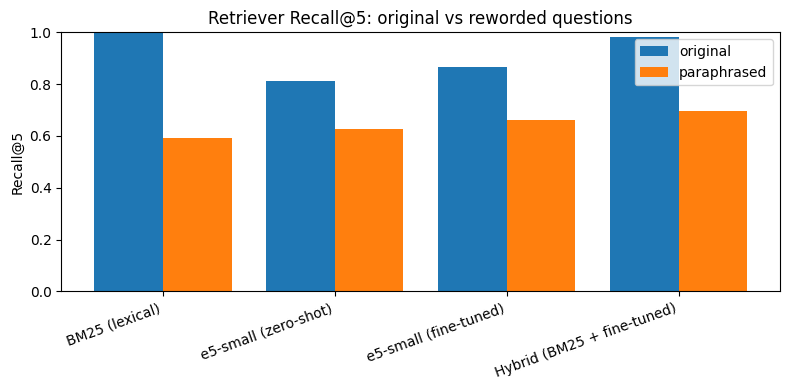

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
names = list(results.index)
x = np.arange(len(names))
ax.bar(x - 0.2, results["Recall@5"], width=0.4, label="original")
ax.bar(x + 0.2, para_r["Recall@5"], width=0.4, label="paraphrased")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
ax.set_ylabel("Recall@5"); ax.set_ylim(0, 1)
ax.set_title("Retriever Recall@5: original vs reworded questions")
ax.legend(); fig.tight_layout()
fig.savefig("eval_recall5.png", dpi=120)
print("saved -> eval_recall5.png")
plt.show()

## 9. Verdict — is the fine-tuned model good?

Plain-language readout of the two tables above.

In [10]:
zs, ftn = "e5-small (zero-shot)", "e5-small (fine-tuned)"

print("=" * 60)
print("VERDICT")
print("=" * 60)

# 1) did fine-tuning help on the original questions?
d_r5  = results.loc[ftn, "Recall@5"] - results.loc[zs, "Recall@5"]
d_mrr = results.loc[ftn, "MRR@10"]  - results.loc[zs, "MRR@10"]
print(f"\n1) Fine-tuning vs zero-shot (original questions):")
print(f"   Recall@5: {results.loc[zs,'Recall@5']:.3f} -> {results.loc[ftn,'Recall@5']:.3f}  "
      f"({d_r5:+.3f})")
print(f"   MRR@10  : {results.loc[zs,'MRR@10']:.3f} -> {results.loc[ftn,'MRR@10']:.3f}  "
      f"({d_mrr:+.3f})")
print("   => fine-tuning HELPED." if d_r5 > 0 and d_mrr > 0 else
      "   => fine-tuning did NOT clearly help — investigate.")

# 2) robustness under rewording
drop = cmp.loc[ftn, "R@1 drop"]
print(f"\n2) Robustness of fine-tuned model under paraphrase:")
print(f"   Recall@1 drop = {drop:+.3f}")
print("   => ROBUST (matches meaning)." if drop <= 0.10 else
      "   => FRAGILE (leaning on word overlap).")

# 3) best overall system
best = results["MRR@10"].idxmax()
print(f"\n3) Best system by MRR@10: {best} ({results.loc[best,'MRR@10']:.3f})")
print("=" * 60)

VERDICT

1) Fine-tuning vs zero-shot (original questions):
   Recall@5: 0.814 -> 0.864  (+0.051)
   MRR@10  : 0.637 -> 0.700  (+0.063)
   => fine-tuning HELPED.

2) Robustness of fine-tuned model under paraphrase:
   Recall@1 drop = +0.254
   => FRAGILE (leaning on word overlap).

3) Best system by MRR@10: BM25 (lexical) (0.895)
